# Student Depression Classification
## Exploratory Data Analysis (EDA) & Data Visualization

### 1. Introduction

Exploratory Data Analysis (EDA) is an essential step in the machine learning workflow. It helps understand the dataset, identify patterns, detect potential data quality issues, and explore relationships between variables before building predictive models.

In this notebook, we perform an exploratory analysis of the Student Depression Dataset using statistical methods and data visualization techniques.

### 2. Dataset Overview

The dataset contains **4,464 student records and 13 features**, covering different aspects of students' lives:

- **Demographic:** Gender, Age, Home Division.
- **Academic:** Current Semester, CGPA.
- **Social and Personal:** Family Background, Relationship Status, Marital Status, Living Style, Friend Circle.
- **Health-related:** Health Condition.
- **Financial:** Cost Without Study.
- **Target Variable:** Depression.

### 3. Objectives

The main objectives of this notebook are:

- Visualize feature distributions using histograms, boxplots, and count plots.
- Explore correlations and pairwise relationships between numerical variables.
- Investigate the distribution of the target variable.
- Examine relationships between individual features and the target variable.

### 4. Data Visualization Techniques

The following visualization techniques will be used:

- **Histograms:** To understand numerical feature distributions.
- **Boxplots:** To examine data spread and potential outliers.
- **Count Plots:** To visualize categorical feature frequencies.
- **Heatmaps:** To explore correlations between numerical variables.
- **Pairplots:** To visualize pairwise relationships between numerical features.
- **Comparative Plots:** To investigate relationships between features and the target variable.

### 5. Expected Outcome

By the end of this notebook, we aim to obtain a better understanding of the dataset, identify meaningful patterns, evaluate potential data quality concerns, and establish a foundation for the preprocessing and machine learning stages.

In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv("../data/raw/Student_Depression_Dataset.csv")
df.head()

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,Female,22,Middle class,Single,Unmarried,Bachelor,8,3.43,Yes,Critical,10113,Chittagong,Yes
1,Male,19,Middle class,Single,Unmarried,Bachelor,2,3.70,Yes,Abnormal,13815,Chittagong,Yes
2,Male,23,Middle class,Single,Unmarried,Family,8,3.28,No,Abnormal,15450,Dhaka,Yes
3,Male,20,Middle class,Complicated,Unmarried,Family,2,3.77,No,Good,17413,Dhaka,No
4,Female,21,Middle class,Single,Unmarried,Family,1,4.00,No,Abnormal,16693,Dhaka,Yes


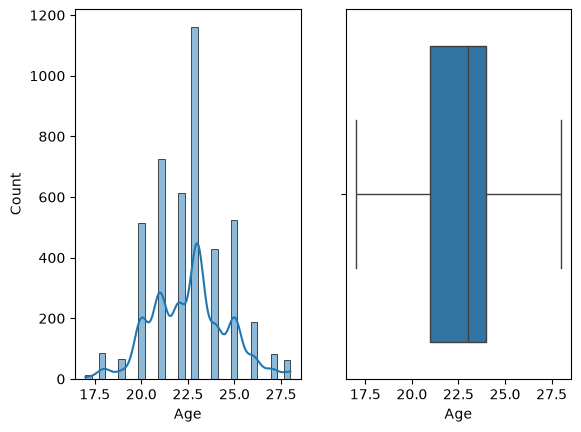

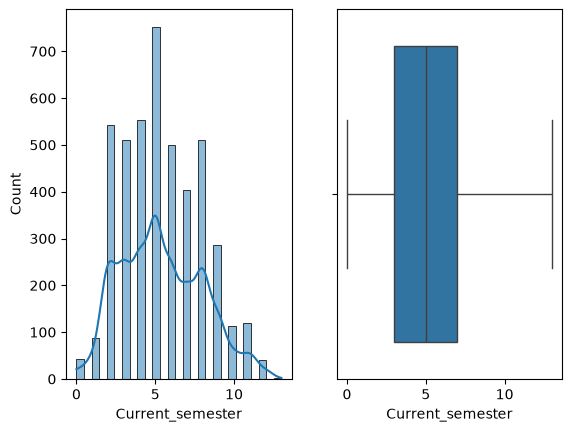

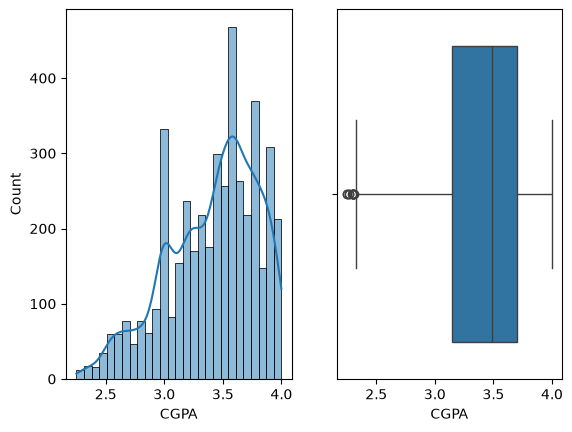

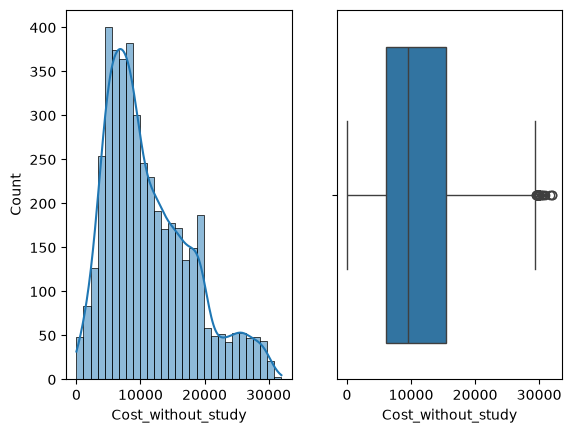

In [4]:
# Visualize the distribution of numerical features
for col in df.select_dtypes('number').columns:
    fig, ax = plt.subplots(1,2)
    sns.histplot(x=df[col],kde=True,ax=ax[0])
    sns.boxplot(x=df[col],ax=ax[1])
    plt.show()

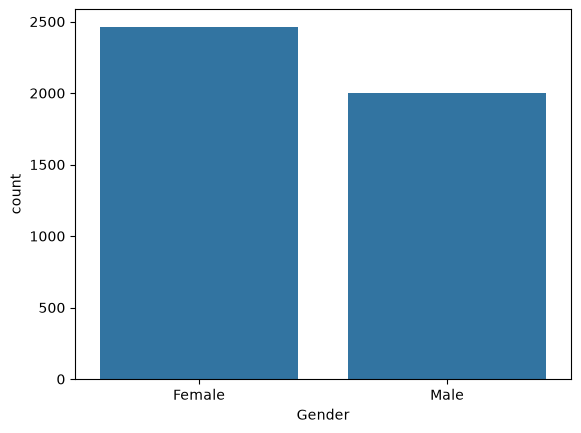

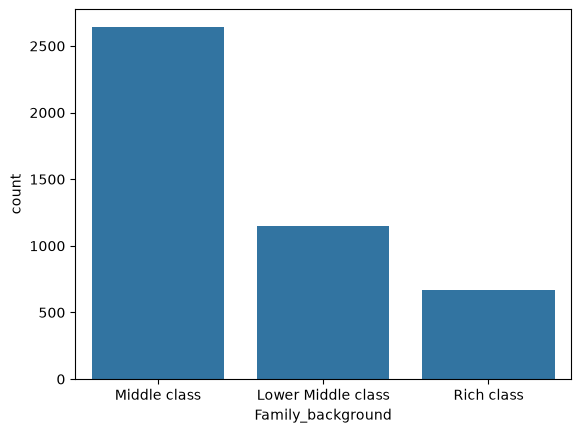

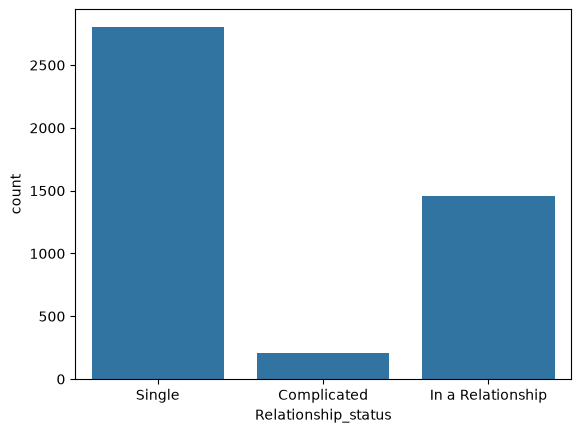

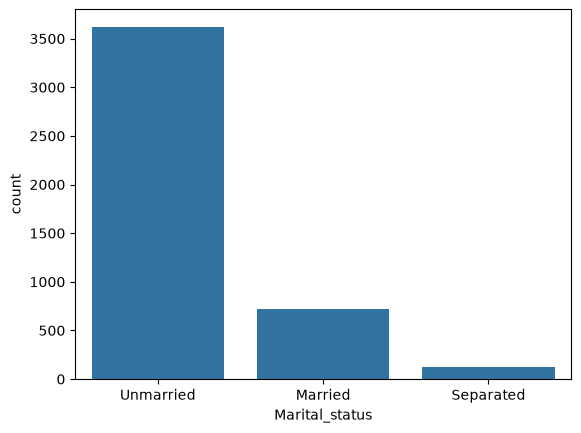

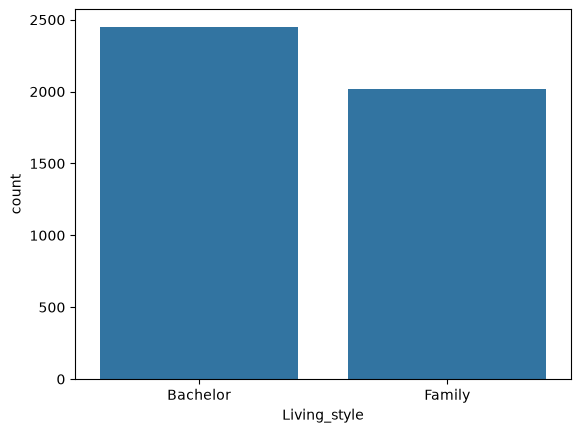

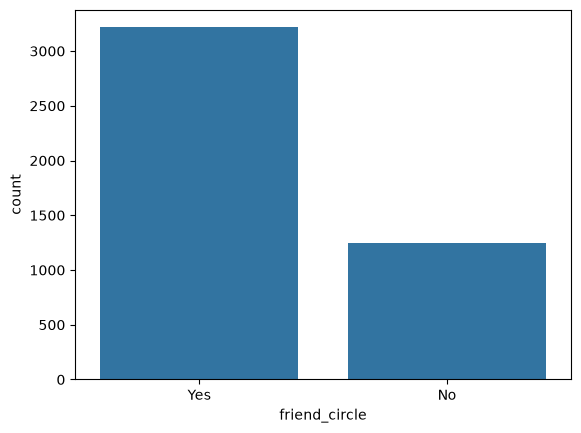

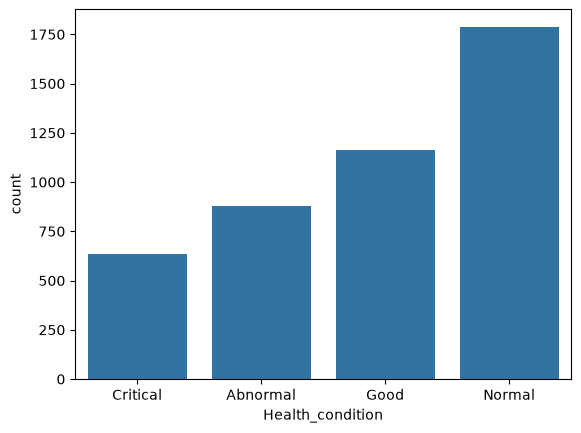

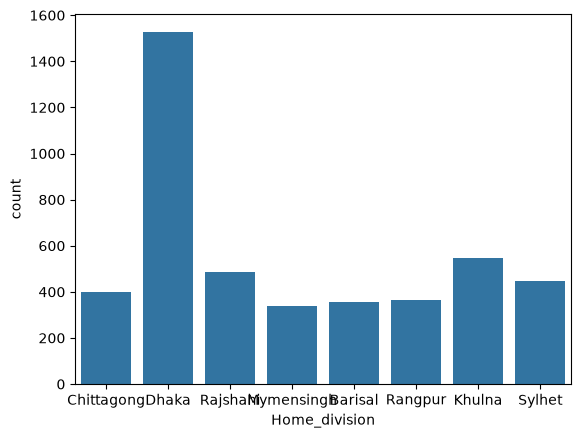

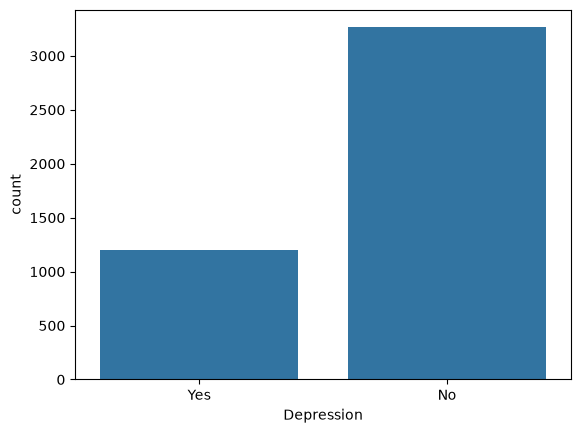

In [5]:
# Visualize the frequency distribution of categorical features
for col in df.select_dtypes('str').columns:
    sns.countplot(x=df[col])
    plt.show()

<Axes: >

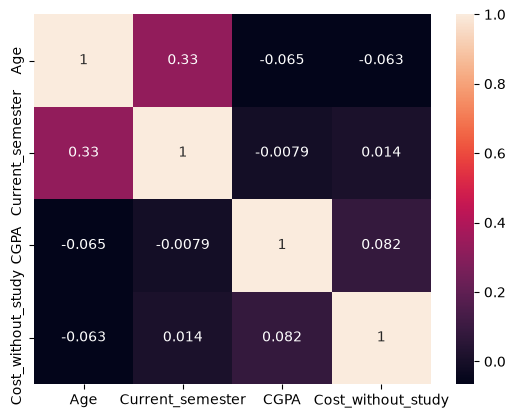

In [6]:
# Calculate the correlation matrix for numerical features
sns.heatmap(df.corr(numeric_only=True),annot=True)

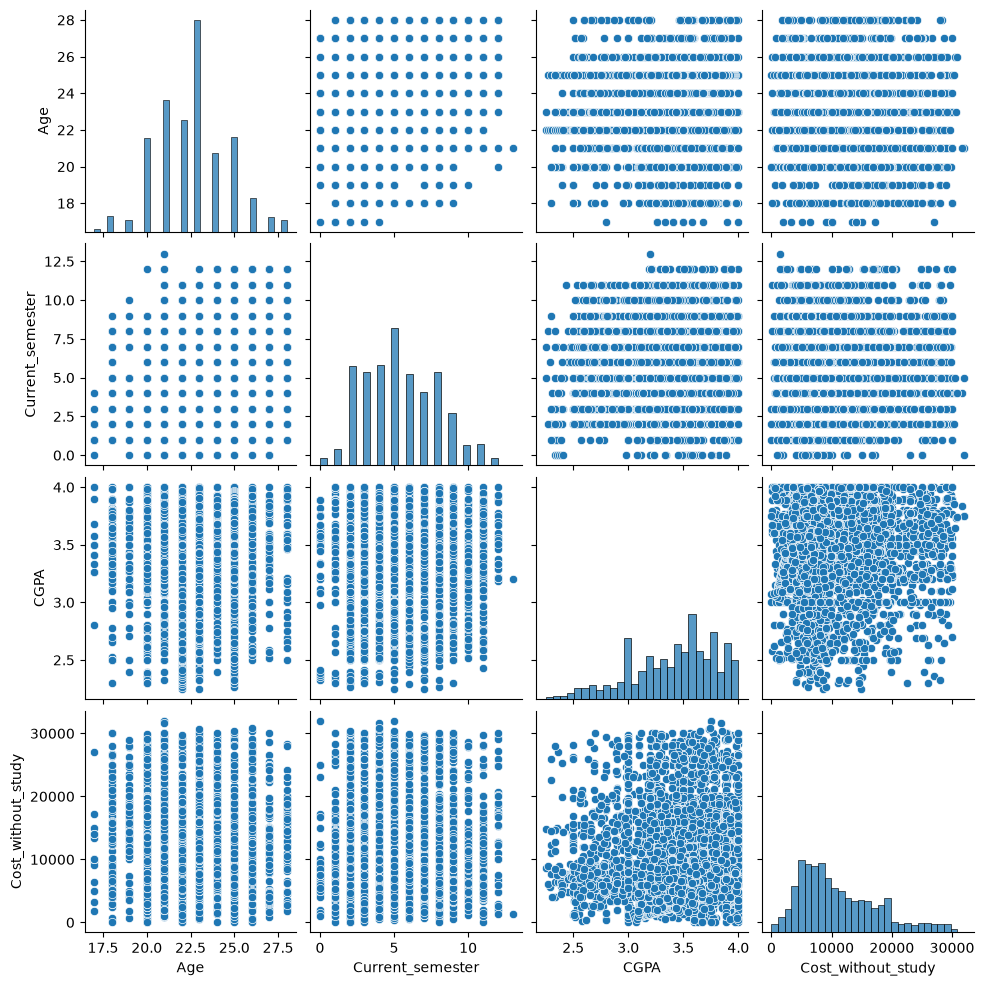

In [7]:
# Select numerical features for pairwise analysis
sns.pairplot(df)

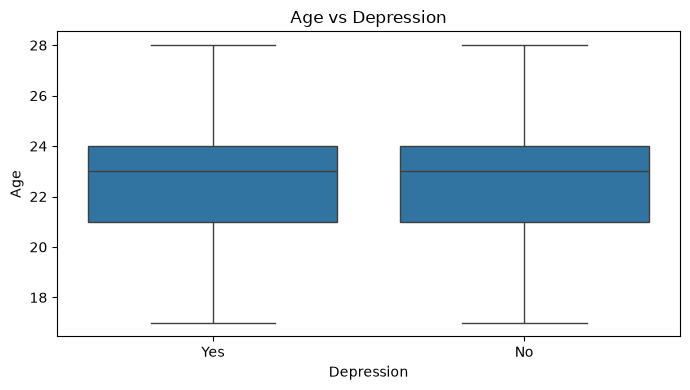

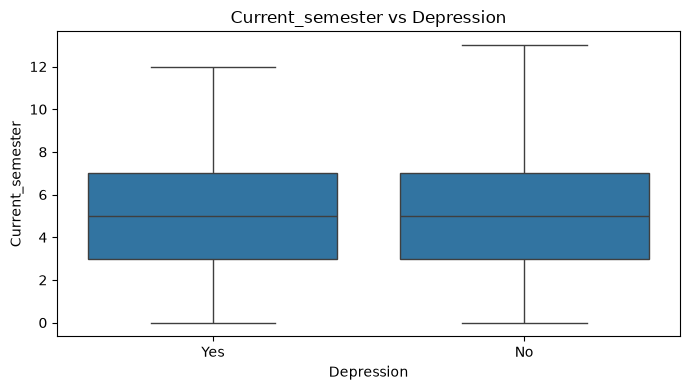

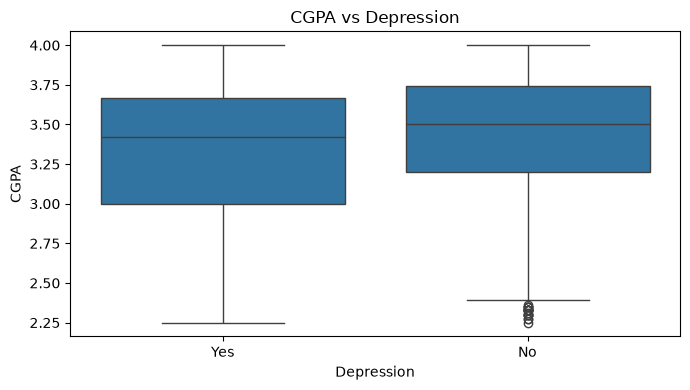

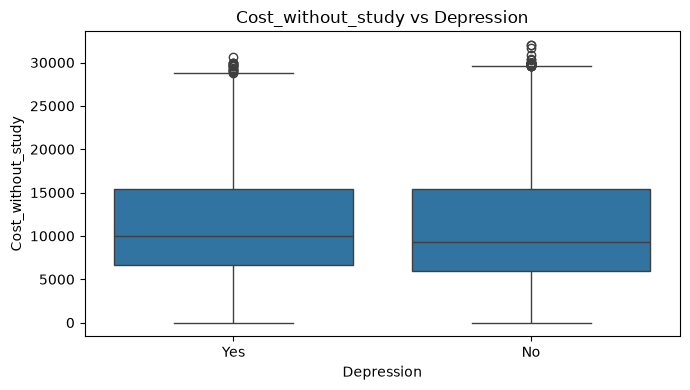

In [10]:
# Compare numerical feature distributions across target classes
numerical_features = df.select_dtypes(include="number").columns

for col in numerical_features:

    # Create a boxplot for each numerical feature
    plt.figure(figsize=(7, 4))
    sns.boxplot(data=df, x="Depression", y=col)

    plt.title(f"{col} vs Depression")
    plt.tight_layout()
    plt.show()

In [12]:
# Calculate the percentage distribution of depression classes
# within each category of every categorical feature
for col in df.select_dtypes('str').columns:

    print(f"\nFeature: {col}")

    proportions = pd.crosstab(
        df[col],
        df["Depression"],
        normalize="index"
    ) * 100

    print(proportions.round(2))


Feature: Gender
Depression     No    Yes
Gender                  
Female      73.40  26.60
Male        72.73  27.27

Feature: Family_background
Depression             No    Yes
Family_background               
Lower Middle class  69.42  30.58
Middle class        72.33  27.67
Rich class          82.41  17.59

Feature: Relationship_status
Depression              No    Yes
Relationship_status              
Complicated          86.76  13.24
In a Relationship    88.54  11.46
Single               64.07  35.93

Feature: Marital_status
Depression         No    Yes
Marital_status              
Married         88.00  12.00
Separated       80.00  20.00
Unmarried       69.88  30.12

Feature: Living_style
Depression       No    Yes
Living_style              
Bachelor      71.66  28.34
Family        74.84  25.16

Feature: friend_circle
Depression        No    Yes
friend_circle              
No             65.73  34.27
Yes            75.96  24.04

Feature: Health_condition
Depression            No  

In [13]:
# Examine the relationship between health condition and depression
health_crosstab = pd.crosstab(
    df["Health_condition"],
    df["Depression"]
)

print(health_crosstab)

Depression          No  Yes
Health_condition           
Abnormal           397  484
Critical             0  634
Good              1162    0
Normal            1704   83


In [14]:
# Calculate depression percentages within each health condition category
health_proportions = pd.crosstab(
    df["Health_condition"],
    df["Depression"],
    normalize="index"
) * 100

print(health_proportions.round(2))

Depression            No     Yes
Health_condition                
Abnormal           45.06   54.94
Critical            0.00  100.00
Good              100.00    0.00
Normal             95.36    4.64


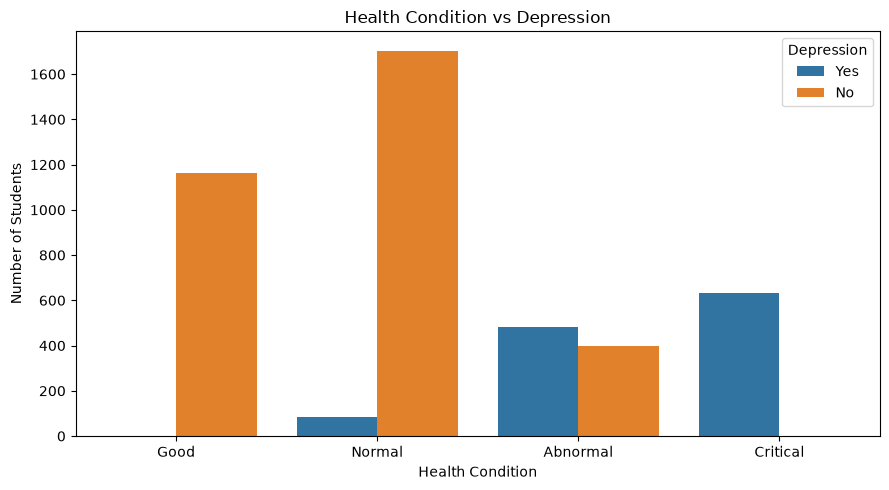

In [15]:
# Visualize the relationship between health condition and depression
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="Health_condition",
    hue="Depression",
    order=["Good", "Normal", "Abnormal", "Critical"]
)

plt.title("Health Condition vs Depression")
plt.xlabel("Health Condition")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()